# Is the matcher's p a probability? (card #88)

The matcher (`src/resolve.py`, card #31) gives each pair of person records a number `p`: its chance that the two records are the same person. ADR-004 lets us call `p` a probability only after a calibration check on validation pairs: a reliability plot and the Brier score.

**What this checks.** Among validation pairs given about 0.7, do about 70% have the same officer id? If the bins with many pairs sit clearly off the diagonal, `p` stays a **score**, not a probability.

**The data:** every file in `data/raw`, the merged crawls, which are kept off git. Pairs are labelled by the register's officer id: the same id is label 1, different ids label 0. The matcher learns from training pairs only, and this notebook checks it on validation pairs only. The crawl also holds the 2022 test companies: their pairs are left out of training and of this check, and the notebook never reads their `failed` labels.

**Masking:** only counts and numbers are shown, never a person's name, a company name or a postcode.

This project is a prototype and is not financial advice.

In [1]:
# Setup: pick up changes to src/ without restarting, and make `import src` work from notebooks/
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

import warnings

import matplotlib.pyplot as plt
import pandas as pd

from src import evaluate, real_slice, resolve

SEED = 42   # the team's one seed, as in main.ipynb; the matcher is the only step that takes one

## Data
`real_slice.load_slice()` runs the team's adapter over every raw file, with the schema checks, then labels and splits the finished query companies with `evaluate.label_failures` and `evaluate.split`: train formed January to September 2021, validation October to December 2021, test 2022. It takes about a minute.

In [2]:
with warnings.catch_warnings(record=True) as caught:   # print the adapter's warnings without a file path
    warnings.simplefilter("always")
    mentions, claims, labels, left_out = real_slice.load_slice()
for warning in caught:
    print("adapter warning:", warning.message)

print("mentions:", mentions["kind"].value_counts().to_dict(), "| claims:", len(claims))
print("query companies labelled:", len(labels), "| left out:", len(left_out))
print("query companies per split:", labels["split"].value_counts().to_dict())

adapter warning: 6 companies have has_insolvency_history but no insolvency file: ['00146161', '00432004', '01233759', '02236989', 'SC083463', 'SC551554']. Their insolvency_on is empty because the data is missing. Leave them out of the labels.
adapter warning: 27 director records skipped: the resignation is dated before the appointment.
mentions: {'company': 108862, 'person': 75498} | claims: 75498
query companies labelled: 13761 | left out: 0
query companies per split: {'test': 6847, 'train': 5362, 'validation': 1552}


## The matcher (#31)
The labelled pairs: two records with the same officer id are label 1, and a pair that blocking proposes with different officer ids is label 0. A pair is validation when one of its two people is a director of a validation company (`real_slice.pair_split`), so no validation pair is ever learned from. The matcher learns only from training pairs whose two records are both at companies formed by September 2021, so no record from the validation period or from 2022 trains it. The officer id is the label, never a feature.

In [3]:
splits = real_slice.person_split(mentions, claims, labels)   # each person record's split, from the company it directs
labelled = resolve.labelled_pairs(mentions)
labelled["split"] = real_slice.pair_split(labelled, splits)
# The matcher learns only from pairs whose two records are at companies formed by the end of the
# training period: a record at a later company, labelled or not (2022 included), keeps its pair out
later = (labelled["split"] == "train") & ~real_slice.train_period_pairs(labelled, mentions, claims)
labelled.loc[later, "split"] = "left out"
train_pairs = labelled[labelled["split"] == "train"].reset_index(drop=True)
model = resolve.train_matcher(resolve.pair_features(train_pairs, mentions), train_pairs["label"], SEED)

shown = labelled[labelled["split"].isin(["train", "validation"])]   # test pairs are never looked at
print(pd.crosstab(shown["split"], shown["label"]).rename(columns={0: "label 0", 1: "label 1"}))
resolve.matcher_weights(model).round(2)

label       label 0  label 1
split                       
train        145518   102213
validation     8441      730


name_similarity        17.88
name_missing            0.00
birth_same              6.16
birth_missing           0.13
postcode_same           1.85
postcode_missing        1.20
nationality_same        1.94
nationality_missing    -0.08
intercept             -24.94
dtype: float64

## Calibration, on validation (#88)
`evaluate.calibration` gives the Brier score, the mean of (p − label)² over the validation pairs: 0 is perfect. The bar to beat is the Brier score of always answering the training share of label 1. It also gives the reliability table: the pairs in five bins of `p`, with the mean `p` in each bin and how many of them have the same officer id. `real_slice.rate` adds that share with its 95% Wilson interval. Where `p` means what it says, the share is close to the mean `p`.

In [4]:
held_out = labelled[labelled["split"] == "validation"].reset_index(drop=True)
p = resolve.match_probability(model, resolve.pair_features(held_out, mentions))
base_share = train_pairs["label"].mean()   # the share of label 1 among the training pairs
brier, bar, table = evaluate.calibration(p, held_out["label"], base_share)
print(f"{len(held_out):,} validation pairs, {int(held_out['label'].sum()):,} of them with the same officer id")
print(f"Brier score: {brier:.3f} | always the training share of label 1 ({base_share:.2f}): {bar:.3f}")

table["share with 95% interval"] = [real_slice.rate(int(k), int(n))
                                    for k, n in zip(table["same_officer_id"], table["pairs"])]
table.round(2)

9,171 validation pairs, 730 of them with the same officer id
Brier score: 0.028 | always the training share of label 1 (0.41): 0.184


,pairs,mean_p,same_officer_id,share with 95% interval
p,,,,
0-0.2,8073,0.00,11,11 of 8073: 0% (0-0%)
0.2-0.4,30,0.28,4,4 of 30: 13% (5-30%)
0.4-0.6,2,0.58,1,1 of 2: 50% (9-91%)
0.6-0.8,651,0.74,365,365 of 651: 56% (52-60%)
0.8-1,415,0.95,349,349 of 415: 84% (80-87%)


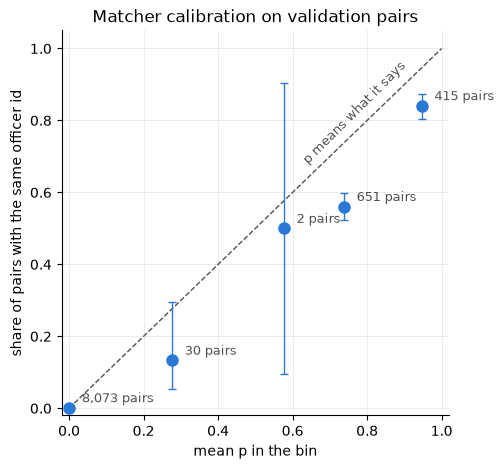

In [5]:
# The reliability plot: one dot per bin, with its 95% interval. On the dashed line, p means what it says.
share = table["same_officer_id"] / table["pairs"]
ends = [real_slice.wilson(int(k), int(n)) for k, n in zip(table["same_officer_id"], table["pairs"])]
below = [middle - low for middle, (low, high) in zip(share, ends)]
above = [high - middle for middle, (low, high) in zip(share, ends)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#52514e")
ax.errorbar(table["mean_p"], share, yerr=[below, above], fmt="o", markersize=8, color="#2a78d6",
            elinewidth=1, capsize=3, zorder=3)
for x, middle, n in zip(table["mean_p"], share, table["pairs"]):
    ax.annotate(f"{n:,} pair" + ("s" if n != 1 else ""), (x, middle), textcoords="offset points",
                xytext=(9, 4), fontsize=9, color="#52514e")
ax.text(0.62, 0.68, "p means what it says", rotation=45, fontsize=9, color="#52514e")
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.05), xlabel="mean p in the bin",
       ylabel="share of pairs with the same officer id", title="Matcher calibration on validation pairs")
ax.grid(color="#e5e4e0", linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## What it shows
**The matcher beats the bar, but `p` is too sure where it is high.** The Brier score on the 9,171 validation pairs is 0.028, far below the bar of 0.184 from always answering the training share of label 1 (0.41). Label 1 is much rarer among the validation pairs (730 of 9,171), and most validation pairs are easy: 8,073 get a `p` of at most 0.2 (mean 0.00), and only 11 of them share an officer id. These pull the average down, so the Brier score alone hides where `p` goes wrong.

The reliability plot shows where. In the two bins above 0.6 the share with the same officer id is clearly below the mean `p`: 365 of 651 pairs (56%, interval 52–60%) at a mean `p` of 0.74, and 349 of 415 (84%, interval 80–87%) at a mean `p` of 0.95. The two middle bins hold too few pairs to say much: 4 of 30 (13%, interval 5–30%) at a mean `p` of 0.28, and 1 of 2 at 0.58.

**Where it could be wrong.** The officer id is the only label, and the register sometimes gives one person two ids. Such a pair is labelled 0 even when the matcher is right that it is one person, so part of the too-sure top bins may be label error rather than matcher error; the hand check (#89) measures how much. The 95% intervals treat every pair as independent, but one person's record can sit in several pairs, so the real intervals are wider than shown. Only validation pairs are used: the matcher never learned from them, and no 2022 test outcome was read.

**Verdict.** By #88's rule, `p` is a **score, not a probability**: the two bins above 0.6, with 651 and 415 pairs, sit clearly below the diagonal.